# The model is fine overall

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/disparate-impact/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/disparate-impact/demo.ipynb)

A screening model scores applicants from two groups. Overall it is good: AUC 0.846, 78.4% accurate. This notebook
asks the per-group questions an auditor asks, and shows why the three most common fairness definitions cannot all
hold when the groups' base rates differ. The world is constructed and declared; every rate is exact.

1. The engine
2. Calibration - exact vs simulation
3. Fine overall, not fine per group
4. Five policies, each enforcing one definition
5. Three definitions cannot all hold
6. Can an audit sample tell?
7. Fix the data instead
8. The chart
9. Try your own

## 1. The engine

Extracted from `fairness.py` at build time. Within each group, scores are normal given the label, so selection rate,
true and false positive rate and precision at any threshold are closed-form. Equalized odds follows Hardt, Price and
Srebro (2016): the group with the better ROC curve is randomised between two thresholds down onto the other's.

In [1]:
from __future__ import annotations

import math
from typing import Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

SEED = 196


MC_REPS = 200_000


GROUPS = ["A", "B"]


WORLD: Dict[str, Dict[str, float]] = {
    "A": {"share": 0.70, "base": 0.40, "mu_q": 1.20, "mu_u": -0.40, "sd": 1.0},
    "B": {"share": 0.30, "base": 0.25, "mu_q": 0.70, "mu_u": -0.30, "sd": 1.0},
}


FOUR_FIFTHS = 0.8


GRID = np.round(np.arange(-2.0, 3.0001, 0.01), 2)  # candidate thresholds


def rates(g: str, t: float, world: Optional[Dict[str, Dict[str, float]]] = None) -> Dict[str, float]:
    """Exact rates for group g when everyone scoring >= t is selected."""
    w = (world or WORLD)[g]
    tpr = float(norm.sf(t, w["mu_q"], w["sd"]))
    fpr = float(norm.sf(t, w["mu_u"], w["sd"]))
    p = w["base"]
    sel = p * tpr + (1 - p) * fpr
    ppv = p * tpr / sel if sel > 0 else float("nan")
    acc = p * tpr + (1 - p) * (1 - fpr)
    return {"tpr": tpr, "fpr": fpr, "sel": sel, "ppv": ppv, "acc": acc}


def mix(a: Dict[str, float], b: Dict[str, float], q: float, base: float) -> Dict[str, float]:
    """Randomise: use threshold a with probability q, threshold b otherwise. TPR and FPR mix linearly."""
    tpr = q * a["tpr"] + (1 - q) * b["tpr"]
    fpr = q * a["fpr"] + (1 - q) * b["fpr"]
    sel = base * tpr + (1 - base) * fpr
    return {"tpr": tpr, "fpr": fpr, "sel": sel, "ppv": base * tpr / sel if sel else float("nan"),
            "acc": base * tpr + (1 - base) * (1 - fpr)}


def auc(g: str, world: Optional[Dict[str, Dict[str, float]]] = None) -> float:
    """Binormal AUC with equal variances: Phi(d / sqrt(2))."""
    w = (world or WORLD)[g]
    return float(norm.cdf((w["mu_q"] - w["mu_u"]) / (w["sd"] * math.sqrt(2))))


def pooled_auc(world: Optional[Dict[str, Dict[str, float]]] = None) -> float:
    """AUC of the score over everyone: P(random qualified scores above random unqualified), mixtures by weight."""
    wd = world or WORLD
    wq = {g: wd[g]["share"] * wd[g]["base"] for g in GROUPS}
    wu = {g: wd[g]["share"] * (1 - wd[g]["base"]) for g in GROUPS}
    sq, su = sum(wq.values()), sum(wu.values())
    tot = 0.0
    for gq in GROUPS:
        for gu in GROUPS:
            d = wd[gq]["mu_q"] - wd[gu]["mu_u"]
            s = math.hypot(wd[gq]["sd"], wd[gu]["sd"])
            tot += (wq[gq] / sq) * (wu[gu] / su) * norm.cdf(d / s)
    return float(tot)


def overall(per: Dict[str, Dict[str, float]], world: Optional[Dict[str, Dict[str, float]]] = None) -> Dict[str, float]:
    wd = world or WORLD
    acc = sum(wd[g]["share"] * per[g]["acc"] for g in GROUPS)
    sel = sum(wd[g]["share"] * per[g]["sel"] for g in GROUPS)
    return {"acc": acc, "sel": sel, "impact_ratio": min(per[g]["sel"] for g in GROUPS) / max(per[g]["sel"] for g in GROUPS)}


def _best(pairs, world) -> Tuple[float, float]:
    """Among threshold pairs, the one with the highest overall accuracy."""
    wd = world
    best, best_acc = None, -1.0
    for ta, tb in pairs:
        a = wd["A"]["share"] * rates("A", ta, wd)["acc"] + wd["B"]["share"] * rates("B", tb, wd)["acc"]
        if a > best_acc:
            best, best_acc = (ta, tb), a
    return best


def _match(metric: str, world) -> List[Tuple[float, float]]:
    """For each threshold of A, the threshold of B that makes `metric` closest to equal."""
    rb = {t: rates("B", t, world)[metric] for t in GRID}
    out = []
    for ta in GRID:
        va = rates("A", ta, world)[metric]
        if va != va:
            continue
        tb = min(GRID, key=lambda t: abs(rb[t] - va) if rb[t] == rb[t] else 9)
        out.append((float(ta), float(tb)))
    return out


def equalized_odds(world: Optional[Dict[str, Dict[str, float]]] = None) -> Dict[str, object]:
    """Hardt, Price & Srebro (2016): equal TPR AND FPR. B's ROC curve lies under A's, so A is randomised down onto
    B's curve: pick B's threshold, then find the mix of two A thresholds hitting the same (FPR, TPR) point.
    Search over B's threshold and A's lower threshold, maximising overall accuracy."""
    wd = world or WORLD
    best = None
    ra = {t: rates("A", t, wd) for t in GRID}
    for tb in GRID[::2]:
        b = rates("B", tb, wd)
        # A point on the chord between A thresholds t1 < t2 hits (fpr_b, tpr_b) only if the chord passes through it.
        for t1 in GRID[::4]:
            a1 = ra[t1]
            if a1["fpr"] < b["fpr"]:
                continue
            # choose t2 so that the chord from a1 through b exits A's curve: solve mix weight on TPR and FPR
            for t2 in GRID[::4]:
                if t2 <= t1:
                    continue
                a2 = ra[t2]
                if a2["fpr"] > b["fpr"]:
                    continue
                q = (b["fpr"] - a2["fpr"]) / (a1["fpr"] - a2["fpr"]) if a1["fpr"] != a2["fpr"] else 0.0
                m = mix(a1, a2, q, wd["A"]["base"])
                if abs(m["tpr"] - b["tpr"]) > 0.003:
                    continue
                acc = wd["A"]["share"] * m["acc"] + wd["B"]["share"] * b["acc"]
                if best is None or acc > best[0]:
                    best = (acc, float(t1), float(t2), float(q), float(tb), m, b)
    _, t1, t2, q, tb, m, b = best
    return {"tA": (t1, t2, q), "tB": tb, "per": {"A": m, "B": b}}


def policies(world: Optional[Dict[str, Dict[str, float]]] = None) -> Dict[str, Dict[str, object]]:
    wd = world or WORLD
    out: Dict[str, Dict[str, object]] = {}
    one = _best([(float(t), float(t)) for t in GRID], wd)
    out["one threshold (max accuracy)"] = {"tA": one[0], "tB": one[1]}
    out["demographic parity"] = dict(zip(("tA", "tB"), _best(_match("sel", wd), wd)))
    out["equal opportunity (TPR)"] = dict(zip(("tA", "tB"), _best(_match("tpr", wd), wd)))
    out["predictive parity (PPV)"] = dict(zip(("tA", "tB"), _best(_match("ppv", wd), wd)))
    for k, v in out.items():
        v["per"] = {"A": rates("A", v["tA"], wd), "B": rates("B", v["tB"], wd)}
    out["equalized odds (TPR+FPR)"] = equalized_odds(wd)
    for v in out.values():
        v["overall"] = overall(v["per"], wd)
        p = v["per"]
        v["gaps"] = {m: p["A"][m] - p["B"][m] for m in ("sel", "tpr", "fpr", "ppv")}
    return out


def impossibility(world: Optional[Dict[str, Dict[str, float]]] = None, tol: float = 0.02) -> Dict[str, object]:
    """Chouldechova (2017): FPR = p / (1 - p) * (1 - PPV) / PPV * TPR within a group. With different base rates p,
    equal PPV and equal TPR force unequal FPR. Check it on every deterministic threshold pair on the grid."""
    wd = world or WORLD
    ra = {t: rates("A", t, wd) for t in GRID}
    rb = {t: rates("B", t, wd) for t in GRID}
    n_pairs = n_two = 0
    n_all = 0
    closest = None
    for ta in GRID[::2]:
        a = ra[ta]
        for tb in GRID[::2]:
            b = rb[tb]
            if a["sel"] < 0.01 or b["sel"] < 0.01:
                continue
            n_pairs += 1
            g = [abs(a["ppv"] - b["ppv"]), abs(a["tpr"] - b["tpr"]), abs(a["fpr"] - b["fpr"])]
            if sum(x <= tol for x in g) >= 2:
                n_two += 1
            if all(x <= tol for x in g):
                n_all += 1
            worst = max(g)
            if closest is None or worst < closest[0]:
                closest = (worst, float(ta), float(tb), g)
    for g in GROUPS:  # the identity itself, at one threshold
        r = rates(g, 0.5, wd)
        p = wd[g]["base"]
        assert abs(r["fpr"] - p / (1 - p) * (1 - r["ppv"]) / r["ppv"] * r["tpr"]) < 1e-12
    return {"pairs": n_pairs, "two_of_three": n_two, "all_three": n_all, "tol": tol,
            "closest": {"worst_gap": closest[0], "tA": closest[1], "tB": closest[2],
                        "ppv_gap": closest[3][0], "tpr_gap": closest[3][1], "fpr_gap": closest[3][2]}}


def audit_power(t: float, n_b_list: List[int], world: Optional[Dict[str, Dict[str, float]]] = None,
                reps: int = 4000, seed: int = SEED) -> List[Dict[str, float]]:
    """An auditor sees n_B applicants from B (and A in proportion) and computes the four-fifths ratio.
    How often does the sample verdict (ratio < 0.8) agree with the population verdict?"""
    wd = world or WORLD
    rng = np.random.default_rng(seed)
    sa, sb = rates("A", t, wd)["sel"], rates("B", t, wd)["sel"]
    truth = min(sa, sb) / max(sa, sb) < FOUR_FIFTHS
    out = []
    for nb in n_b_list:
        na = int(round(nb * wd["A"]["share"] / wd["B"]["share"]))
        ka = rng.binomial(na, sa, reps)
        kb = rng.binomial(nb, sb, reps)
        pa, pb = ka / na, kb / nb
        with np.errstate(divide="ignore", invalid="ignore"):
            ratio = np.minimum(pa, pb) / np.maximum(pa, pb)
        ratio = np.nan_to_num(ratio, nan=1.0)
        verdict = ratio < FOUR_FIFTHS
        lo, hi = np.percentile(ratio, [5, 95])
        out.append({"n_B": nb, "agree": float((verdict == truth).mean()), "ratio_p5": float(lo), "ratio_p95": float(hi)})
    return out


def simulate(policy: Dict[str, object], n: int = MC_REPS, seed: int = SEED,
             world: Optional[Dict[str, Dict[str, float]]] = None) -> Dict[str, Dict[str, Tuple[int, int]]]:
    """Draw applicants, score them, apply the policy (randomising where it says so). Counts for Wilson checks."""
    wd = world or WORLD
    rng = np.random.default_rng(seed)
    out = {}
    for g in GROUPS:
        m = rng.binomial(n, wd[g]["share"])
        q = rng.random(m) < wd[g]["base"]
        s = np.where(q, rng.normal(wd[g]["mu_q"], wd[g]["sd"], m), rng.normal(wd[g]["mu_u"], wd[g]["sd"], m))
        t = policy["tA"] if g == "A" else policy["tB"]
        if isinstance(t, tuple):
            t1, t2, w = t
            use1 = rng.random(m) < w
            sel = np.where(use1, s >= t1, s >= t2)
        else:
            sel = s >= t
        out[g] = {"sel": (int(sel.sum()), m), "tpr": (int((sel & q).sum()), int(q.sum())),
                  "fpr": (int((sel & ~q).sum()), int((~q).sum())), "ppv": (int((sel & q).sum()), int(sel.sum()))}
    return out


def wilson(k: int, n: int, z: float = 2.5758) -> Tuple[float, float]:
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h


def calibrate(world: Optional[Dict[str, Dict[str, float]]] = None, n: int = MC_REPS) -> List[Dict[str, object]]:
    rows = []
    for name, pol in policies(world).items():
        mc = simulate(pol, n=n, world=world)
        for g in GROUPS:
            for m in ("sel", "tpr", "fpr", "ppv"):
                k, nn = mc[g][m]
                lo, hi = wilson(k, nn)
                ex = pol["per"][g][m]
                rows.append({"policy": name, "group": g, "metric": m, "exact": ex, "mc": k / nn,
                             "inside": bool(lo <= ex <= hi)})
    return rows


def parse_world(text: str) -> Dict[str, Dict[str, float]]:
    """`B.base=0.3, B.mu_q=1.0` overrides. Unknown keys or bad numbers raise ValueError."""
    wd = {g: dict(v) for g, v in WORLD.items()}
    for part in [p.strip() for p in text.split(",") if p.strip()]:
        if "=" not in part or "." not in part.split("=")[0]:
            raise ValueError(f"expected group.key=value, got {part!r}")
        key, val = [x.strip() for x in part.split("=", 1)]
        g, k = key.split(".", 1)
        if g not in wd or k not in wd[g]:
            raise ValueError(f"unknown parameter {key!r}; groups {GROUPS}, keys {list(WORLD['A'])}")
        try:
            wd[g][k] = float(val)
        except ValueError:
            raise ValueError(f"{key} needs a number, got {val!r}") from None
    if abs(sum(wd[g]["share"] for g in GROUPS) - 1) > 1e-9:
        raise ValueError("group shares must sum to 1")
    for g in GROUPS:
        if not 0 < wd[g]["base"] < 1 or wd[g]["sd"] <= 0:
            raise ValueError("base rates must be in (0, 1) and sd positive")
    return wd


def data_fix(world: Optional[Dict[str, Dict[str, float]]] = None) -> Dict[str, object]:
    """The remedy no threshold can provide: make B's score as informative as A's (same qualified-unqualified gap),
    base rates unchanged. Returns the fixed world's policies plus the gap it set."""
    wd = {g: dict(v) for g, v in (world or WORLD).items()}
    gap = wd["A"]["mu_q"] - wd["A"]["mu_u"]
    wd["B"]["mu_q"] = wd["B"]["mu_u"] + gap
    return {"world": wd, "auc_B": auc("B", wd), "policies": policies(wd)}


ORDER = ['one threshold (max accuracy)', 'demographic parity', 'equal opportunity (TPR)', 'predictive parity (PPV)', 'equalized odds (TPR+FPR)']


def show(pols):
    print(f"{'policy':<30} {'accuracy':>9} {'4/5 ratio':>10} {'sel A':>6} {'sel B':>6} {'TPR A':>6} {'TPR B':>6} "
          f"{'FPR A':>6} {'FPR B':>6} {'PPV A':>6} {'PPV B':>6}")
    for n in ORDER:
        p, o = pols[n]["per"], pols[n]["overall"]
        print(f"{n:<30} {o['acc']:>9.1%} {o['impact_ratio']:>10.3f} {p['A']['sel']:>6.1%} {p['B']['sel']:>6.1%} "
              f"{p['A']['tpr']:>6.1%} {p['B']['tpr']:>6.1%} {p['A']['fpr']:>6.1%} {p['B']['fpr']:>6.1%} "
              f"{p['A']['ppv']:>6.1%} {p['B']['ppv']:>6.1%}")

## 2. Calibration - exact vs simulation

`simulate` draws applicants, scores them and applies each policy, coin flips included. Each exact rate should sit
inside the 99% Wilson interval of its simulated share.

**Resolution of the instrument.** The study in `evidence.txt` draws 200,000 applicants per policy; this notebook
draws 50,000 so it runs in seconds, so its intervals are about 2x wider. The exact numbers below do not depend
on this.

In [2]:
cal = calibrate(n=50000)
print(f"{sum(r['inside'] for r in cal)}/{len(cal)} exact rates inside the simulation's 99% Wilson interval")

40/40 exact rates inside the simulation's 99% Wilson interval


## 3. Fine overall, not fine per group

Group B is 30% of applicants, 25% of them qualified against A's 40%, and the score separates B's qualified from its
unqualified less well (AUC 0.760 against 0.871), because the training data held fewer of them. One threshold for
everyone selects a qualified A applicant 65.9% of the time and a qualified B applicant 46.4% of the time.

In [3]:
print(f"{'group':<6} {'share':>6} {'base rate':>10} {'AUC':>6}")
for g in GROUPS:
    print(f"{g:<6} {WORLD[g]['share']:>6.0%} {WORLD[g]['base']:>10.0%} {auc(g):>6.3f}")
pols = policies()
one = pols["one threshold (max accuracy)"]
o = one["overall"]
print(f"pooled AUC {pooled_auc():.3f}, accuracy {o['acc']:.1%} at one threshold ({one['tA']:.2f}); "
      f"four-fifths ratio {o['impact_ratio']:.3f} (rule: >= {FOUR_FIFTHS})")
print(f"qualified applicants selected: A {one['per']['A']['tpr']:.1%}, B {one['per']['B']['tpr']:.1%}")

group   share  base rate    AUC
A         70%        40%  0.871
B         30%        25%  0.760
pooled AUC 0.846, accuracy 78.4% at one threshold (0.79); four-fifths ratio 0.657 (rule: >= 0.8)
qualified applicants selected: A 65.9%, B 46.4%


## 4. Five policies, each enforcing one definition

Demographic parity equalises selection (the four-fifths rule's view). Equal opportunity equalises the share of
qualified applicants selected. Predictive parity equalises precision. Equalized odds equalises both true and false
positive rates. Each policy meets its own definition and breaks at least one other. Equalized odds on this model
only works by levelling A down: 12% of A applicants are judged at a threshold that admits almost everyone and the
rest at a much stricter one, and accuracy falls 6.3 points. Predictive parity is the most accurate of the five and
selects 3.2% of B.

In [4]:
show(pols)
eo = pols["equalized odds (TPR+FPR)"]
t1, t2, q = eo["tA"]
print(f"equalized odds: A is randomised - threshold {t1:.2f} for {q:.0%} of A applicants, {t2:.2f} for the rest; B at {eo['tB']:.2f}")

policy                          accuracy  4/5 ratio  sel A  sel B  TPR A  TPR B  FPR A  FPR B  PPV A  PPV B
one threshold (max accuracy)       78.4%      0.657  33.4%  21.9%  65.9%  46.4%  11.7%  13.8%  79.0%  52.9%
demographic parity                 77.3%      0.995  30.5%  30.4%  61.8%  57.9%   9.7%  21.2%  81.0%  47.7%
equal opportunity (TPR)            76.9%      0.914  29.5%  32.3%  60.3%  60.3%   9.0%  23.0%  81.7%  46.7%
predictive parity (PPV)            78.6%      0.083  38.8%   3.2%  72.9%   9.7%  16.1%   1.1%  75.1%  75.1%
equalized odds (TPR+FPR)           72.2%      0.813  26.7%  21.7%  46.3%  46.0%  13.6%  13.6%  69.5%  53.1%
equalized odds: A is randomised - threshold -1.72 for 12% of A applicants, 1.48 for the rest; B at 0.80


## 5. Three definitions cannot all hold

Within any group, FPR = p / (1 - p) x (1 - PPV) / PPV x TPR (Chouldechova, 2017). If base rates p differ, equal
precision and equal true positive rate force unequal false positive rates. Checked by brute force: every
deterministic threshold pair on the grid.

In [5]:
imp = impossibility()
c = imp["closest"]
print(f"threshold pairs checked: {imp['pairs']:,}; within {imp['tol']:.0%} on two of PPV/TPR/FPR: {imp['two_of_three']:,}; on all three: {imp['all_three']}")
print(f"closest pair (A {c['tA']:.2f}, B {c['tB']:.2f}): PPV gap {c['ppv_gap']:.3f}, TPR gap {c['tpr_gap']:.3f}, FPR gap {c['fpr_gap']:.3f}")

threshold pairs checked: 56,977; within 2% on two of PPV/TPR/FPR: 931; on all three: 0
closest pair (A -2.00, B -1.20): PPV gap 0.129, TPR gap 0.028, FPR gap 0.129


## 6. Can an audit sample tell?

An auditor rarely sees the population. Drawing applicants in the real proportions and computing the four-fifths ratio
on the sample, the verdict matches the population's only 84% of the time with 100 applicants from B. It takes about
500 before it is right 98% of the time.

In [6]:
au = audit_power(one["tA"], [25, 50, 100, 200, 500, 1000, 2000])
print(f"{'n of B':>7} {'verdict agrees':>15} {'ratio 5th pct':>14} {'ratio 95th pct':>15}")
for r in au:
    print(f"{r['n_B']:>7} {r['agree']:>15.1%} {r['ratio_p5']:>14.3f} {r['ratio_p95']:>15.3f}")

 n of B  verdict agrees  ratio 5th pct  ratio 95th pct
     25           73.0%          0.258           0.958
     50           76.2%          0.364           0.949
    100           84.5%          0.444           0.896
    200           92.2%          0.507           0.830
    500           98.5%          0.560           0.764
   1000           99.9%          0.588           0.728
   2000          100.0%          0.608           0.708


## 7. Fix the data instead

Every policy above moves thresholds on a score that is weaker for B. Make B's score as informative as A's, base rates
unchanged, and one threshold passes the four-fifths rule (0.657 to 0.828) while accuracy rises (78.4% to 80.2%).
Equalized odds now costs nothing. The precision gap stays, because it comes from the base rates and no amount of
model quality removes it, and equalising true positive rates now fails the four-fifths rule.

In [7]:
fix = data_fix()
show(fix["policies"])
fo = fix["policies"]["one threshold (max accuracy)"]["overall"]
print(f"one threshold now: accuracy {o['acc']:.1%} -> {fo['acc']:.1%}, four-fifths ratio {o['impact_ratio']:.3f} -> {fo['impact_ratio']:.3f}")

policy                          accuracy  4/5 ratio  sel A  sel B  TPR A  TPR B  FPR A  FPR B  PPV A  PPV B
one threshold (max accuracy)       80.2%      0.828  32.9%  27.2%  65.2%  68.8%  11.3%  13.3%  79.3%  63.2%
demographic parity                 79.6%      0.996  32.3%  32.2%  64.4%  75.2%  10.9%  17.9%  79.7%  58.4%
equal opportunity (TPR)            80.4%      0.759  33.9%  25.7%  66.6%  66.6%  12.1%  12.1%  78.6%  64.7%
predictive parity (PPV)            80.7%      0.428  38.0%  16.2%  71.9%  49.2%  15.4%   5.3%  75.7%  75.7%
equalized odds (TPR+FPR)           80.4%      0.760  34.2%  26.0%  67.0%  67.0%  12.3%  12.3%  78.4%  64.5%
one threshold now: accuracy 78.4% -> 80.2%, four-fifths ratio 0.657 -> 0.828


## 8. The chart

The full audit figure is `fairness_audit.png` (built by `make_chart.py` from `results.json`). Here, the two ROC
curves: equalized odds can only live where both groups can reach, which is under B's curve.

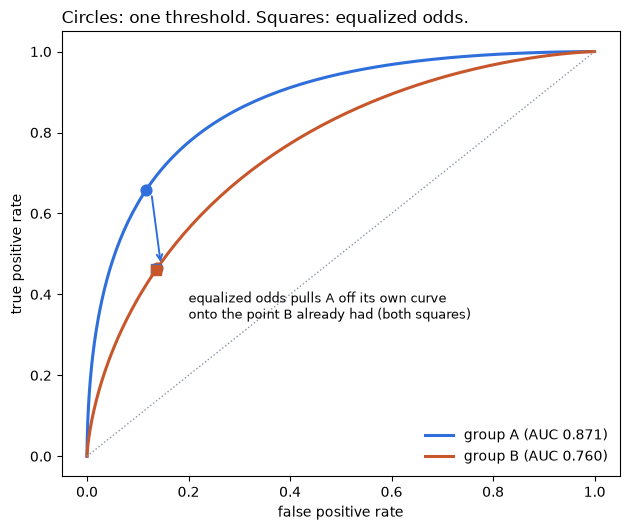

In [8]:
ts = np.linspace(-4, 5, 300)
fig, ax = plt.subplots(figsize=(6.4, 5.4))
for g, col in (("A", "#2f6fdb"), ("B", "#c8562b")):
    fpr = [rates(g, t)["fpr"] for t in ts]
    tpr = [rates(g, t)["tpr"] for t in ts]
    ax.plot(fpr, tpr, color=col, lw=2.2, label=f"group {g} (AUC {auc(g):.3f})")
for n, mk in (("one threshold (max accuracy)", "o"), ("equalized odds (TPR+FPR)", "s")):
    p = pols[n]["per"]
    for g, col in (("A", "#2f6fdb"), ("B", "#c8562b")):
        ax.scatter(p[g]["fpr"], p[g]["tpr"], color=col, marker=mk, s=60, zorder=3)
a0, a1 = pols["one threshold (max accuracy)"]["per"]["A"], pols["equalized odds (TPR+FPR)"]["per"]["A"]
ax.annotate("", xy=(a1["fpr"] + 0.01, a1["tpr"] + 0.01), xytext=(a0["fpr"] + 0.01, a0["tpr"] - 0.01),
            arrowprops=dict(arrowstyle="->", color="#2f6fdb", lw=1.4))
ax.text(0.20, 0.38, "equalized odds pulls A off its own curve", fontsize=9)
ax.text(0.20, 0.34, "onto the point B already had (both squares)", fontsize=9)
ax.plot([0, 1], [0, 1], color="#8a94a3", ls=":", lw=1)
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("Circles: one threshold. Squares: equalized odds.", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- Fine overall (AUC 0.846, 78.4% accurate), and a qualified B applicant is selected 46.4% of the time against 65.9%
  for A. The four-fifths ratio is 0.657.
- Each fairness definition can be met by a threshold policy, and each one breaks another. None of 56,977 threshold
  pairs meets equal precision, true positive rate and false positive rate within 2 points.
- Equalized odds on this model costs 6.3 points of accuracy by levelling A down. Predictive parity is the most
  accurate policy and selects 3.2% of B.
- A four-fifths audit with 100 applicants from B gets the verdict wrong about 1 time in 6.
- Fixing B's data does what no threshold can: passes four-fifths and raises accuracy. The precision gap remains,
  because base rates differ.

## 9. Try your own

In [9]:
# Your groups, e.g. a smaller base-rate gap and a better score for B:
# mine = parse_world("B.base=0.35, B.mu_q=1.0")
# show(policies(mine)); print(impossibility(mine)["all_three"])

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version takes your
own groups: `pip install -r requirements.txt && streamlit run app.py`.

Sibling builds: [`resume-screener`](../../document-intelligence/resume-screener) is the kind of model this audits;
[`pii-detector`](../../data-infra-toolkit/pii-detector) and [`consent-tracker`](../consent-tracker) cover privacy, which is a different
question from fairness.